# Figure 5: Cell Painting Validation Analysis

Validates PhenoCompass predictions against an experimental Cell Painting screen for FOXO3A activity, including ROC curves, UMAP visualizations, and anchor cosine-similarity heatmaps.

This notebook generates:
1. Cell Painting similarity-to-anchors strip plot
2. Partial ROC curve for mTOR/PI3K drug prediction
3. Compound bioactivity proportion barplot
4. UMAP visualizations (anchors/drugs/predictions, anchor scores, top MoAs, FOXO3A screen)
5. Partial ROC curve for FOXO3A hit prediction
6. Off-target effects (non-PI3K hits) barplot
7. FOXO3A nuclear enrichment strip plot
8. mTOR/PI3K anchor cosine similarity heatmaps (Cell Painting validation embeddings and JUMP DINO-TVN embeddings)

## Notebook Outputs

This notebook caches `cp_cellprofiler_univariate_metrics.csv` and `cp_phenosimilarity_scores.csv` in `data/cellpainting_validation/`. The phenosimilarity scores are consumed by `Fig5_hit_analysis.ipynb`, so run this notebook first.

## 1. Setup and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics.pairwise import cosine_similarity
from collections import defaultdict
from scipy.stats import hypergeom
from anndata import AnnData
import scanpy as sc
import umap

from phenocompass.evaluation import univariate_metric_all_random
from phenocompass.evaluation import compute_phenosimilarity_scores

import phenocompass
_nb_dir = os.path.abspath(os.path.join(os.path.dirname(phenocompass.__file__), "..", "..", "notebooks"))
sys.path.insert(0, _nb_dir)
from utils import setup_publication_style, save_figure, save_figure_data, REPO_ROOT

%matplotlib inline

BASE_DIR = str(REPO_ROOT)
setup_publication_style(BASE_DIR)

# --- Output directories ---
DATA_DIR = os.path.join(BASE_DIR, "data", "cellpainting_validation")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "cellpainting_validation")
FINAL_DATA_DIR = os.path.join(BASE_DIR, "final_data")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

FORCE_RECOMPUTE = False

BEST_RUN = "norm_mad_pca128_bc_tvn"

print("Figures will be saved to figures/")
print("Intermediate data will be saved to data/")

No normalization for SPS. Feature removed!


No normalization for AvgIpc. Feature removed!


Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'


Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'


Skipped loading some Jax models, missing a dependency. No module named 'haiku'


Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


Figures will be saved to figures/
Intermediate data will be saved to data/


## 2. Cell Painting Bioactivity

In [2]:
# Load CellProfiler features (well-level)
cp_features_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, f"validation/validation_cp_sweep/{BEST_RUN}/centered.parquet"))
print("Loaded CellProfiler features")

# Keep a copy with VehicleControl for phenosimilarity null distribution
cp_features_df_all = cp_features_df.copy()

# Filter out vehicle controls
cp_features_df = cp_features_df[cp_features_df["Metadata_Remarks"] != "VehicleControl"]

# Map compound IDs to their categories
compound_id_category_mapper = {compound_id: category for compound_id, category
                                in cp_features_df.sort_values("Metadata_Category")[["Metadata_COMPOUND_ID", "Metadata_Category"]].drop_duplicates().values}

Loaded CellProfiler features


In [3]:
# Get feature columns (all non-metadata)
cp_feature_columns = [c for c in cp_features_df.columns if not c.startswith("Metadata_")]
print("Number of features")

# Run univariate bioactivity analysis
cache_path = os.path.join(DATA_DIR, "cp_cellprofiler_univariate_metrics.csv")
if os.path.exists(cache_path) and not FORCE_RECOMPUTE:
    cp_bioactivity_metrics = pd.read_csv(cache_path)
    print("Loaded cached metrics")
else:
    cp_bioactivity_results = univariate_metric_all_random(
        cp_features_df,
        columns=cp_feature_columns,
        perturbation_name_field="Metadata_COMPOUND_ID",
        perturbation_id_field="Metadata_COMPOUND_ID",
        perturbation_type_field="Metadata_Remarks",
        n_samples=9999,
        significance_level=0.01,
    )
    cp_bioactivity_metrics = cp_bioactivity_results["metrics"]
    cp_bioactivity_metrics.to_csv(cache_path, index=False)
    print("Cached metrics to")

Number of features
Loaded cached metrics


In [4]:
# Map bioactivity compounds to category names
cp_bioactivity_metrics["Metadata_Category"] = cp_bioactivity_metrics["Metadata_COMPOUND_ID"].map(compound_id_category_mapper)

## 2b. CellProfiler Phenosimilarity Scores

In [5]:
# Load anchor compounds for phenosimilarity scoring
anchor_compounds_for_scoring = cp_features_df[cp_features_df["Metadata_Category"] == "PI3K/mTOR Anchors"]["Metadata_COMPOUND_ID"].unique().tolist()

# Compute phenosimilarity scores with plate-matched null
cache_path = os.path.join(DATA_DIR, "cp_phenosimilarity_scores.csv")
if os.path.exists(cache_path) and not FORCE_RECOMPUTE:
    cp_phenosim_df = pd.read_csv(cache_path)
    print("Loaded cached phenosimilarity scores")
else:
    cp_phenosim_df = compute_phenosimilarity_scores(
        well_df=cp_features_df_all,
        anchor_compounds=anchor_compounds_for_scoring,
        perturbation_column="Metadata_COMPOUND_ID",
        annotation_column="Metadata_Remarks",
        negative_control_annotation="VehicleControl",
        plate_column="Metadata_Plate",
    )
    cp_phenosim_df.to_csv(cache_path, index=False)
    print("Cached phenosimilarity scores to")

Loaded cached phenosimilarity scores


In [6]:
# Map compound IDs to their categories
cp_phenosim_df["Metadata_Category"] = cp_phenosim_df["Metadata_COMPOUND_ID"].map(compound_id_category_mapper)

## 3. Load Annotations Data

In [7]:
# Load mTOR/PI3K anchor compound annotations from consolidated file
all_anchors_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "compound_annotations/anchor_compounds.tsv"), sep="\t")
mtor_pi3k_anchors_df = all_anchors_df[all_anchors_df["cluster_moa"] == "PI3K/mTOR"].copy()

# Load control compound annotations (canonical SMILES pre-computed in cleanup notebook)
gprobe_tool_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "compound_annotations/cp_validation_control_annotations.tsv"), sep="\t")
gprobe_tool_df.index = gprobe_tool_df["COMPOUND_ID"].values
gprobe_canonical_smiles_dict = gprobe_tool_df["canonical_SMILES"].to_dict()
gprobe_compound_id_moa_mapper = {compound_id: moa for compound_id, moa
                                 in gprobe_tool_df[["COMPOUND_ID", "MOA"]].values.astype(str)}

# Identify control compounds with nan or Unknown MOA
nan_unknown_control_compounds = gprobe_tool_df[gprobe_tool_df["MOA"].astype(str).isin(["nan", "Unknown"])]["COMPOUND_ID"].values

## 4. Load Validation Results

### 4.1 Load FOXO3A Results

In [8]:
significance_thresh = 1e-4
p_value_column = "empnullplatematched_p_value"

foxo3a_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "validation/foxo3a_results.tsv"), sep="\t")

# Derive stat view (one row per perturbagen) and z view (full rows)
foxo3a_stat_df = foxo3a_df.drop_duplicates(subset="COMPOUND_ID")
foxo3a_z_df = foxo3a_df

# Map Compound ID to FOXO3A z-score
compound_id_foxo3a_mapper = {compound_id: z_score for compound_id, z_score
                             in foxo3a_z_df[["COMPOUND_ID", "mean_clip_5"]].values}

### 4.2 Load Cell Painting Results

### 4.3 Load Cell Painting Validation Hit-Calling

In [9]:
# FDR corrected p-values
from statsmodels.stats.multitest import fdrcorrection

cp_phenosim_df["empnullplatematched_fdr"] = fdrcorrection(cp_phenosim_df["empnullplatematched_p_value"])[1]

In [10]:
# Load DINO anchor scores
dino_anchor_scores_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "validation/jump_cell_painting.anchor_scores.tsv"), sep="\t")
dino_anchor_scores_df.index = dino_anchor_scores_df["Metadata_smile"].values
dino_anchor_scores_df["empnullplatematched_fdr"] = fdrcorrection(dino_anchor_scores_df["empnullplatematched_p_value"])[1]

In [11]:
# Load CP validation control compounds
control_cp_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "compound_annotations/cp_validation_controls_in_jump.tsv"), sep="\t")

# Identify overlap of control compounds between JUMP and Cell Painting validation
cond = (control_cp_df["Metadata_In_JUMP"]) & (~control_cp_df["Metadata_COMPOUND_ID"].isin(nan_unknown_control_compounds))
jump_validation_overlap_compounds = control_cp_df[cond]["Metadata_COMPOUND_ID"].values
jump_validation_overlap_smiles = control_cp_df[cond]["Metadata_In_JUMP_SMILES"].values

# Focus on pheno-similarity of control compounds
control_cp_phenosim_df = cp_phenosim_df[cp_phenosim_df["Metadata_COMPOUND_ID"].isin(jump_validation_overlap_compounds)]
control_cp_phenosim_df = control_cp_phenosim_df[["Metadata_COMPOUND_ID", "phenosimilarity_score", "empnullplatematched_p_value"]].drop_duplicates(ignore_index=True)
control_cp_phenosim_df.index = control_cp_phenosim_df["Metadata_COMPOUND_ID"].values

# Focus on pheno-similarity of PhenoCompass compounds
phenocompass_compounds = cp_features_df[cp_features_df["Metadata_Category"] == "PhenoCompass"]["Metadata_COMPOUND_ID"].unique().tolist()

In [12]:
# Compute thresholds and hit rates
p_thresh = 0.01
percentile = 99

sig_column = "empnullplatematched_p_value"

# Compute percentile thresholds (based on control compounds)
dino_thresh = np.percentile(dino_anchor_scores_df.loc[jump_validation_overlap_smiles]["jump_anchor_score"], percentile)
jumpval_thresh = np.percentile(control_cp_phenosim_df.loc[jump_validation_overlap_compounds]["phenosimilarity_score"], percentile)

# Exclude PI3K/mTOR anchors from consideration for calculating hit rates
dino_anchor_scores_df["is_anchor"] = dino_anchor_scores_df["Metadata_smile"].isin(mtor_pi3k_anchors_df["canonical_SMILES"].values)
dino_anchor_scores_df = dino_anchor_scores_df[~dino_anchor_scores_df["is_anchor"]]

# Compute hit rates
dino_anchor_scores_df["cp_hit"] = (dino_anchor_scores_df["jump_anchor_score"] > dino_thresh) & (dino_anchor_scores_df[sig_column] < p_thresh)
cp_phenosim_df["cp_hit"] = (cp_phenosim_df["phenosimilarity_score"] > jumpval_thresh) & (cp_phenosim_df[sig_column] < p_thresh)

dino_hit_rate = dino_anchor_scores_df["cp_hit"].sum() / dino_anchor_scores_df.shape[0]
phenocompass_cp_phenosim_df = cp_phenosim_df[cp_phenosim_df["Metadata_COMPOUND_ID"].isin(phenocompass_compounds)]
phenocompass_hit_rate = phenocompass_cp_phenosim_df["cp_hit"].sum() / phenocompass_cp_phenosim_df.shape[0]

print(f"JUMP Hits: ({dino_anchor_scores_df['cp_hit'].sum()}/{dino_anchor_scores_df.shape[0]}) {dino_hit_rate:.5f}")
print(f"PhenoCompass Hits: ({phenocompass_cp_phenosim_df['cp_hit'].sum()}/{phenocompass_cp_phenosim_df.shape[0]}) {phenocompass_hit_rate:.5f}")
print("Enrichment")

cp_hits = cp_phenosim_df[cp_phenosim_df["cp_hit"]]["Metadata_COMPOUND_ID"].values

JUMP Hits: (56/108822) 0.00051
PhenoCompass Hits: (11/396) 0.02778
Enrichment


In [13]:
pi3k_mtor_drug_controls = cp_phenosim_df[cp_phenosim_df["Metadata_Category"] == "mTOR/PI3K Drugs ($+$)"]["Metadata_COMPOUND_ID"].values
print(len(set(cp_hits) & set(pi3k_mtor_drug_controls))/len(set(pi3k_mtor_drug_controls)))

0.5106382978723404


## 5. Cell Painting Similarity to Anchors

In [14]:
plot_category_rank_mapper = {"mTOR/PI3K Drugs ($+$)": 1,
                             "PhenoCompass": 2,
                             "PhenoCompass\n(PI3K Drug Anchors)": 3,
                             "Tanimoto Similarity Lookup": 4,
                            }

Figure already exists


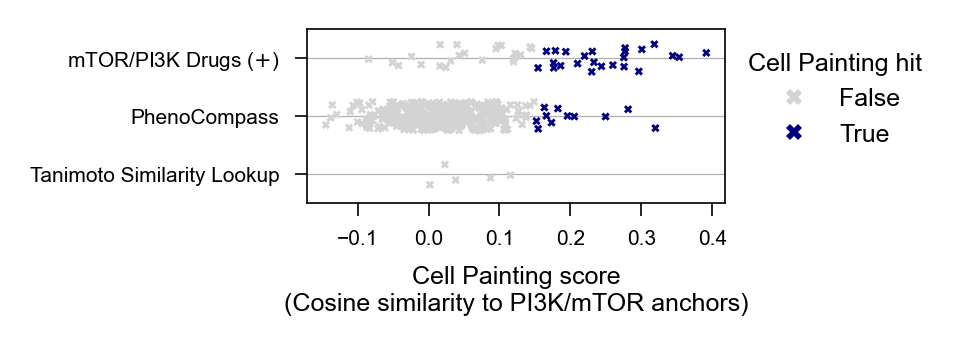

In [15]:
# --- Similarity to anchors strip plot ---
fig_path = os.path.join(FIGURE_DIR, "Fig5_cell_painting.similarity_to_anchors.pdf")

categories_to_exclude = ["gProbe Compounds", "Plate Controls", "PhenoCompass\n(PI3K Drug Anchors)", "PI3K/mTOR Anchors (ignore)", "PI3K/mTOR Anchors"]
plot_df = cp_phenosim_df[~cp_phenosim_df["Metadata_Category"].isin(categories_to_exclude)]
plot_df["category_rank"] = plot_df["Metadata_Category"].map(plot_category_rank_mapper)

hit_column = "cp_hit"

plt.figure(figsize=(1.8, plot_df["Metadata_Category"].nunique() * 0.25))
sns.stripplot(x="phenosimilarity_score", y="Metadata_Category", hue=hit_column,
              data=plot_df.sort_values(["category_rank", hit_column]),
              s=2, jitter=0.25, palette=["lightgrey", "navy"], marker="X")
plt.xlabel("Cell Painting score\n(Cosine similarity to PI3K/mTOR anchors)")
plt.ylabel("")
plt.grid(axis="y", linewidth=0.3)
plt.legend(bbox_to_anchor=(1, 1), title="Cell Painting hit", title_fontsize=6, markerscale=2)

save_figure(fig_path, FORCE_RECOMPUTE)

## 6. Prediction Accuracies of mTOR/PI3K Drugs

Figure already exists


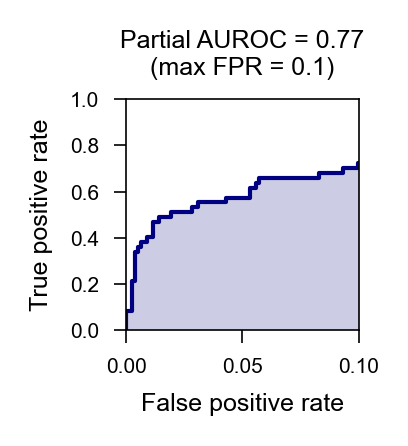

In [16]:
y_pred_neg = cp_phenosim_df[cp_phenosim_df["Metadata_Category"] == "gProbe Compounds"]["phenosimilarity_score"].values.tolist()
y_pred_pos = cp_phenosim_df[cp_phenosim_df["Metadata_Category"] == "mTOR/PI3K Drugs ($+$)"]["phenosimilarity_score"].values.tolist()

y_true = [0] * len(y_pred_neg) + [1] * len(y_pred_pos)
y_pred = y_pred_neg + y_pred_pos

# --- Partial ROC curve ---
fig_path = os.path.join(FIGURE_DIR, "FigS11_cell_painting.mtor_pi3k_drugs.partial_roc_curve.pdf")

fpr, tpr, thresholds = roc_curve(y_true, y_pred)
plt.figure(figsize=(1, 1))
plt.plot(fpr[fpr < 0.15], tpr[fpr < 0.15], color='navy', lw=1)
plt.fill_between(fpr[fpr < 0.15], tpr[fpr < 0.15], color='navy', alpha=0.2, edgecolor=None)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title("Partial AUROC = {:.2f}\n(max FPR = 0.1)".format(roc_auc_score(y_true, y_pred, max_fpr=0.1)))
plt.xlim([0, 0.1])
plt.ylim([0, 1])

save_figure(fig_path, FORCE_RECOMPUTE)

## 7. Compound Bioactivity

In [17]:
bioactivity_plot_name_upper = {"mTOR/PI3K Drugs ($+$)": "PI3K/mTOR drug",
                               "Tanimoto Similarity Lookup": "Tanimoto similarity\nlookup",
                               "gProbe Compounds": "Other drug",
                               "PhenoCompass": "PhenoCompass",
                               "JUMP Dataset": "JUMP dataset"}

Percent bioactive (FDR): 0.276
Figure already exists


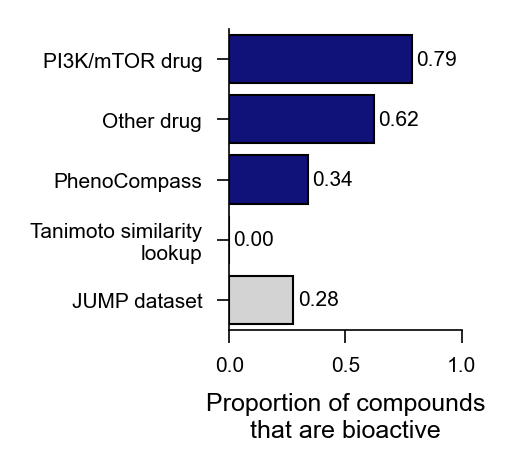

In [18]:
# Load JUMP bioactivity data (FDR correction pre-applied in cleanup notebook)
p_thresh = 0.01

jump_univariate_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "jump_map/jump_bioactivity_predictions.tsv"), sep="\t")
jump_univariate_df.index = jump_univariate_df["Metadata_SMILES"].values

print("Percent bioactive (FDR): {:.3f}".format((jump_univariate_df["significant_bh"]).mean()))

cp_bioactivity_metrics["significant"] = cp_bioactivity_metrics["significant"].astype(bool)
bioactive_prop_df = cp_bioactivity_metrics.groupby("Metadata_Category")["significant"].mean().reset_index()
bioactive_prop_df.sort_values("significant", ascending=False, inplace=True)

categories_to_exclude = ["Plate Controls", "PI3K/mTOR Anchors", "PI3K/mTOR Anchors (ignore)", "PhenoCompass\n(PI3K Drug Anchors)"]
bioactive_prop_df = bioactive_prop_df[~bioactive_prop_df["Metadata_Category"].isin(categories_to_exclude)]

bioactive_prop_df = pd.concat([bioactive_prop_df, pd.DataFrame({"Metadata_Category": ["JUMP Dataset"],
                                "significant": [(jump_univariate_df["significant_bh"]).mean()]})]).copy()

bioactive_prop_df["Metadata_Category"] = bioactive_prop_df["Metadata_Category"].map(bioactivity_plot_name_upper)

fig_path = os.path.join(FIGURE_DIR, "FigS11_cell_painting.prop_bioactive.pdf")

plt.figure(figsize=(1., 1.3))
ax = sns.barplot(x="significant", y="Metadata_Category", data=bioactive_prop_df,
                 palette=["darkblue"] * (len(bioactive_prop_df) - 1) + ["lightgrey"],
                 edgecolor="black", linewidth=0.5)
plt.xlim([0, 1])
plt.xlabel("Proportion of compounds\nthat are bioactive")
plt.ylabel("")

# Remove the top and right axes lines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=5, label_type='edge', padding=1, color='black')

save_figure(fig_path, FORCE_RECOMPUTE)

## 8. Pheno-Similarity of Compounds

In [19]:
import pickle as pkl

with open(os.path.join(FINAL_DATA_DIR, "compound_annotations/cp_validation_opentarget_annotations.pkl"), "rb") as f:
    validation_cp_control_annotations = pkl.load(f)

# Map OpenTarget annotations to compounds
compound_moa_mapper = {}
for gene_set, compound_id_list in validation_cp_control_annotations["sets"].items():
    for compound_id in compound_id_list:
        compound_moa_mapper[compound_id] = gene_set

### 8.1 Identifying Best Biological Recall MoAs

In [20]:
multivariate_all_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, f"validation/validation_cp_sweep/{BEST_RUN}/per_term_metrics.moa.csv"))

cond = (multivariate_all_df["metric"] == "AUROC") & (~multivariate_all_df["term"].isna()) & \
       (multivariate_all_df["max_fpr"] == 0.1) & (multivariate_all_df["locality"] == "global")

top_terms_df = multivariate_all_df[cond].groupby("term")["value"].mean().sort_values(ascending=False).head(9).reset_index()
top_maplib_moas = top_terms_df["term"].values

top_terms_df

,term,value
0,HSP90,1.000000
1,SHP2,0.997727
2,CBP,0.995909
3,LRRK2,0.929091
4,HDAC2,0.920455
5,TNKS2,0.900076
6,Syk,0.892273
7,PI3K-A,0.799317
8,PI3K-D,0.776737


### 8.2 Build AnnData from Morphological Embeddings

In [21]:
from anndata import AnnData

cp_features_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, f"validation/validation_cp_sweep/{BEST_RUN}/centered.parquet"))

cp_feature_columns = [c for c in cp_features_df.columns if not c.startswith("Metadata_")]
cp_metadata_columns = [c for c in cp_features_df.columns if c.startswith("Metadata_")]

# Retain only relevant categories for plotting
categories_to_plot = ["PhenoCompass", "gProbe Compounds",
                      "mTOR/PI3K Drugs ($+$)",
                      "PI3K/mTOR Anchors", "PI3K/mTOR Anchors (ignore)"]

filtered_cp_features_df = cp_features_df[cp_features_df["Metadata_Category"].isin(categories_to_plot)]
cp_features_agg_df = filtered_cp_features_df.groupby(["Metadata_COMPOUND_ID", "Metadata_Category"],observed=True)[cp_feature_columns].mean().reset_index()

filtered_adata = AnnData(cp_features_agg_df[cp_feature_columns].values)
filtered_adata.obs = cp_features_agg_df[["Metadata_COMPOUND_ID", "Metadata_Category"]].copy()

# Map phenosimilarity scores to compounds
compound_id_category_phenosimilarity_mapper = {(row["Metadata_COMPOUND_ID"], row["Metadata_Category"]): row["phenosimilarity_score"]
                                              for _, row in cp_phenosim_df[["Metadata_COMPOUND_ID", "Metadata_Category", "phenosimilarity_score"]].iterrows()}

filtered_adata.obs["phenosimilarity_score"] = [compound_id_category_phenosimilarity_mapper.get((row["Metadata_COMPOUND_ID"], row["Metadata_Category"]), np.nan)
                                                for _, row in filtered_adata.obs.iterrows()]

# Map FOXO3A screen scores to compounds
filtered_adata.obs["foxo3a_z"] = filtered_adata.obs["Metadata_COMPOUND_ID"].map(compound_id_foxo3a_mapper)

print("Filtered AnnData shape")

Filtered AnnData shape


### 8.3 UMAP

In [22]:
# Compute UMAP

umap_adata = filtered_adata.copy()

umap_adata.obsm["X_umap"] = umap.UMAP(
    n_neighbors=25, min_dist=0.1, negative_sample_rate=40, repulsion_strength=1.5, metric="cosine",
    random_state=0
).fit_transform(umap_adata.X)

Figure already exists


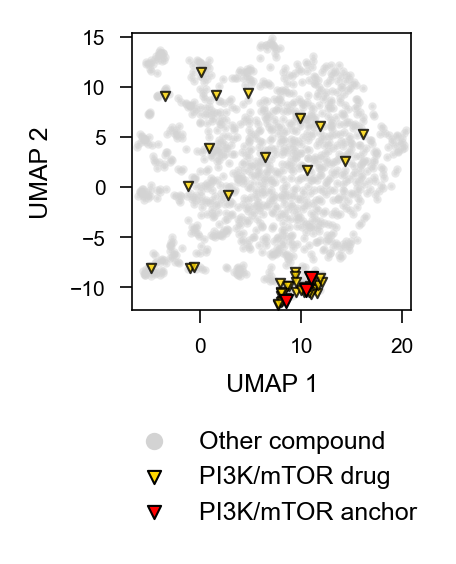

In [23]:
# --- UMAP: anchors, drugs, predictions ---
fig_path = os.path.join(FIGURE_DIR, "Fig5_cell_painting.umap.anchors_drugs_predictions.pdf")

plt.figure(figsize=(1.2, 1.2))
# Define all plotting properties for each category in a dict
plot_params = {
    "PI3K/mTOR Anchors": dict(label="PI3K/mTOR anchor", alpha=1., marker="v", s=10, color="red", edgecolor="black", linewidth=0.5),
    "mTOR/PI3K Drugs ($+$)": dict(label="PI3K/mTOR drug", alpha=0.8, marker="v", s=5, color="gold", edgecolor="black", linewidth=0.5),
    "Other compound": dict(label="Other compound", alpha=0.5, s=1, color="lightgrey"),
}

# Group PhenoCompass and gProbe Compounds together as "Other compound"
other_mask = umap_adata.obs["Metadata_Category"].isin(["PhenoCompass", "gProbe Compounds"])
for n in ["Other compound", "mTOR/PI3K Drugs ($+$)", "PI3K/mTOR Anchors"]:
    if n == "Other compound":
        group_adata = umap_adata[other_mask]
    else:
        group_adata = umap_adata[umap_adata.obs["Metadata_Category"] == n]
    umap_X = group_adata.obsm["X_umap"]
    params = plot_params[n]
    plt.scatter(umap_X[:, 0], umap_X[:, 1], **params)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.xlim([umap_adata.obsm["X_umap"][:, 0].min() - 0.5, umap_adata.obsm["X_umap"][:, 0].max() + 0.5])
plt.ylim([umap_adata.obsm["X_umap"][:, 1].min() - 0.5, umap_adata.obsm["X_umap"][:, 1].max() + 0.5])
leg = plt.legend(bbox_to_anchor=(1.1, -0.35))
for handle in leg.legend_handles:
    handle.set_sizes([10.])
    if isinstance(handle._alpha, float):
        handle.set_alpha(1.0)
    else:
        handle.set_alpha(np.ones(len(handle._alpha)))

save_figure(fig_path, FORCE_RECOMPUTE)

Figure already exists


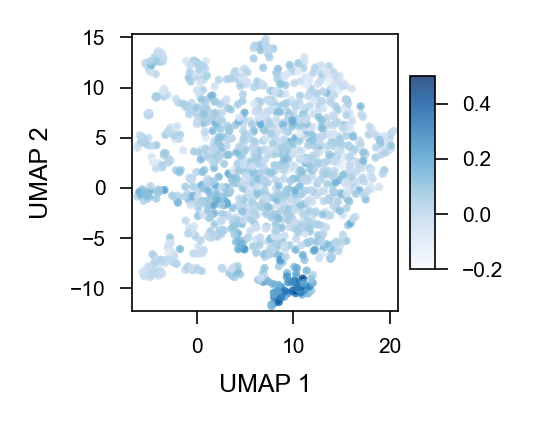

In [24]:
# --- UMAP: anchor scores (with colorbar) ---
fig_path = os.path.join(FIGURE_DIR, "Fig5_cell_painting.umap.anchor_scores.pdf")

fig, ax = plt.subplots(figsize=(1.3, 1.2))
sc = ax.scatter(
    umap_adata.obsm["X_umap"][:, 0],
    umap_adata.obsm["X_umap"][:, 1],
    c=umap_adata.obs["phenosimilarity_score"], cmap="Blues", s=1, alpha=0.8,
    vmin=-0.2, vmax=0.5
)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_xlim([umap_adata.obsm["X_umap"][:, 0].min() - 0.5, umap_adata.obsm["X_umap"][:, 0].max() + 0.5])
ax.set_ylim([umap_adata.obsm["X_umap"][:, 1].min() - 0.5, umap_adata.obsm["X_umap"][:, 1].max() + 0.5])

# Make the colorbar a little wider and shorter, explicitly set ticks
cbar = fig.colorbar(
    sc, ax=ax, 
    fraction=0.08,    # Make colorbar wider
    pad=0.04,         # Slightly closer to plot
    aspect=8         # Make colorbar shorter (smaller aspect -> shorter)
)
sc.set_clim(-0.2, 0.5)
cbar.set_ticks([-0.2, 0.0, 0.2, 0.4])

save_figure(fig_path, FORCE_RECOMPUTE)

Figure already exists


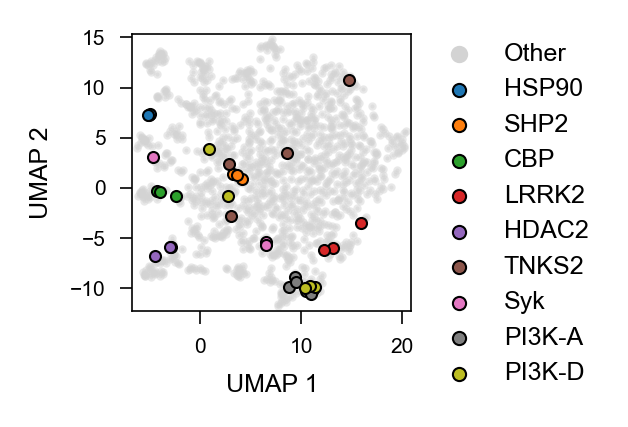

Figure already exists


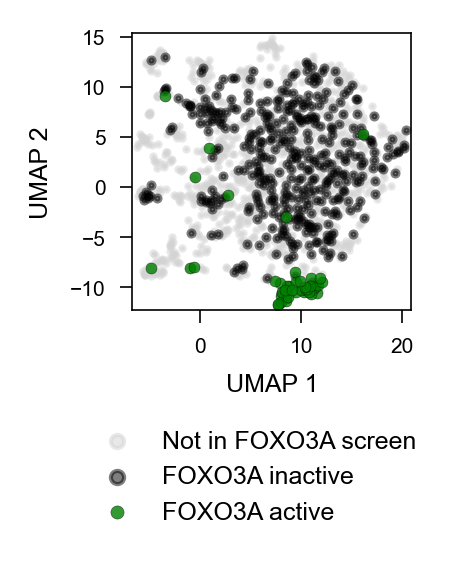

In [25]:
# --- UMAP: top MoAs ---
fig_path = os.path.join(FIGURE_DIR, "FigS11_cell_painting.umap.top_moas.pdf")

# Map OpenTarget annotations to compounds
umap_adata.obs["Metadata_MoA"] = umap_adata.obs["Metadata_COMPOUND_ID"].map(compound_moa_mapper)

plt.figure(figsize=(1.2, 1.2))
plt.scatter(umap_adata.obsm["X_umap"][:, 0],
            umap_adata.obsm["X_umap"][:, 1],
            c="lightgrey", alpha=0.5, s=1, label="Other")
for n in top_maplib_moas:
    group_adata = umap_adata[umap_adata.obs["Metadata_MoA"] == n]
    umap_X = group_adata.obsm["X_umap"]
    plt.scatter(umap_X[:, 0], umap_X[:, 1], label=n, alpha=1., s=7, edgecolor="black", linewidth=0.5)
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.xlim([umap_adata.obsm["X_umap"][:, 0].min() - 0.5, umap_adata.obsm["X_umap"][:, 0].max() + 0.5])
plt.ylim([umap_adata.obsm["X_umap"][:, 1].min() - 0.5, umap_adata.obsm["X_umap"][:, 1].max() + 0.5])
leg = plt.legend(bbox_to_anchor=(1., 1.05), ncol=1)
for handle in leg.legend_handles:
    handle.set_sizes([10.])
    if isinstance(handle._alpha, float):
        handle.set_alpha(1.0)
    else:
        handle.set_alpha(np.ones(len(handle._alpha)))

save_figure(fig_path, FORCE_RECOMPUTE)

# --- UMAP: FOXO3A screen ---
fig_path = os.path.join(FIGURE_DIR, "Fig5_cell_painting.umap.foxo3a_screen.pdf")

plt.figure(figsize=(1.2, 1.2))
plt.scatter(umap_adata[umap_adata.obs["foxo3a_z"].isna()].obsm["X_umap"][:, 0],
            umap_adata[umap_adata.obs["foxo3a_z"].isna()].obsm["X_umap"][:, 1],
            c="lightgrey", s=1, alpha=0.5, label="Not in FOXO3A screen")

subplot_adata = umap_adata[~umap_adata.obs["foxo3a_z"].isna()]
plt.scatter(subplot_adata[subplot_adata.obs["foxo3a_z"] < 1].obsm["X_umap"][:, 0],
            subplot_adata[subplot_adata.obs["foxo3a_z"] < 1].obsm["X_umap"][:, 1],
            c="black", s=2, alpha=0.5, label="FOXO3A inactive")
plt.scatter(subplot_adata[subplot_adata.obs["foxo3a_z"] > 1].obsm["X_umap"][:, 0],
            subplot_adata[subplot_adata.obs["foxo3a_z"] > 1].obsm["X_umap"][:, 1],
            c="green", edgecolor="black", linewidth=0.1, s=7, alpha=0.8, label="FOXO3A active")

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.xlim([umap_adata.obsm["X_umap"][:, 0].min() - 0.5, umap_adata.obsm["X_umap"][:, 0].max() + 0.5])
plt.ylim([umap_adata.obsm["X_umap"][:, 1].min() - 0.5, umap_adata.obsm["X_umap"][:, 1].max() + 0.5])
leg = plt.legend(bbox_to_anchor=(1.1, -0.35))
for handle in leg.legend_handles:
    handle.set_sizes([10.])
    if handle.get_label() == "Not in FOXO3A Screen":
        handle.set_alpha(1.)

save_figure(fig_path, FORCE_RECOMPUTE)

In [26]:
fig_adata = umap_adata.copy()
fig_adata.obs = fig_adata.obs[["Metadata_COMPOUND_ID", "Metadata_Category",
                               "phenosimilarity_score", "foxo3a_z"]]
fig_data_path = os.path.join(FIGURE_DIR, "Fig5_S11_cellpainting_umap_data.h5ad")
save_figure_data(fig_adata, fig_data_path, FORCE_RECOMPUTE)

Figure data already exists


## 9. CP Predictor of FOXO3A Hits

Figure already exists


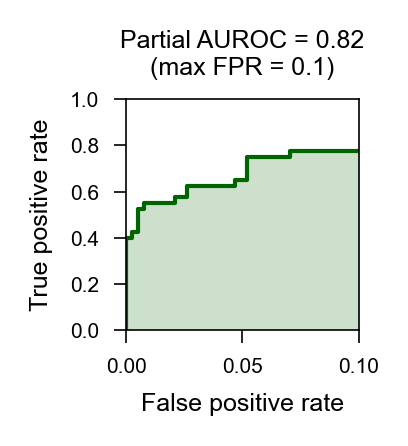

In [27]:
plot_adata = filtered_adata[~filtered_adata.obs["foxo3a_z"].isna()].copy()
plot_adata = plot_adata[~plot_adata.obs["Metadata_Category"].isin(["PI3K/mTOR Anchors", "PI3K/mTOR Anchors (ignore)"])]

y_true = plot_adata.obs["foxo3a_z"] > 1
y_pred = plot_adata.obs["phenosimilarity_score"]

# --- Partial ROC curve ---
fig_path = os.path.join(FIGURE_DIR, "FigS11_foxo3a_hits.partial_roc_curve.pdf")

fpr, tpr, thresholds = roc_curve(y_true, y_pred)
plt.figure(figsize=(1, 1))
plt.plot(fpr[fpr < 0.15], tpr[fpr < 0.15], color='darkgreen', lw=1)
plt.fill_between(fpr[fpr < 0.15], tpr[fpr < 0.15], color='darkgreen', alpha=0.2, edgecolor=None)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title("Partial AUROC = {:.2f}\n(max FPR = 0.1)".format(roc_auc_score(y_true, y_pred, max_fpr=0.1)))
plt.xlim([0, 0.1])
plt.ylim([0, 1])

save_figure(fig_path, FORCE_RECOMPUTE)

## 10. Nearest Neighbor Analysis of Non-Hit Compounds

In [28]:
# PhenoCompass compounds
model_adata = filtered_adata[filtered_adata.obs["Metadata_Category"].isin(["PhenoCompass"])].copy()
model_adata = model_adata[~model_adata.obs["Metadata_COMPOUND_ID"].isin(cp_hits)]

# Annotated compounds
other_adata = filtered_adata[~filtered_adata.obs["Metadata_Category"].isin(["PhenoCompass"])].copy()
other_adata.obs["Metadata_MoA"] = other_adata.obs["Metadata_COMPOUND_ID"].map(gprobe_compound_id_moa_mapper)
other_adata.obs["Metadata_MoA"] = ["PI3K/mTOR" if (cat in "mTOR/PI3K Drugs ($+$)" or "PI3K" in moa) else moa
                                   for moa, cat in other_adata.obs[["Metadata_MoA","Metadata_Category"]].values.astype(str)]
other_adata = other_adata[other_adata.obs["Metadata_MoA"] != "nan"]


cossim = cosine_similarity(model_adata.X, other_adata.X)

all_counts_df = pd.DataFrame(other_adata.obs["Metadata_MoA"].values[np.argmax(cossim, axis=1)],
                             columns=["Metadata_MoA"]).value_counts().reset_index()

enrichment_dict_all = defaultdict(list)
for moa, x in all_counts_df[["Metadata_MoA", "count"]].values:
    M = other_adata.shape[0]
    n = (other_adata.obs["Metadata_MoA"] == moa).sum()
    N = model_adata.shape[0]
    pval = hypergeom.sf(x - 1, M, n, N)

    enrichment_dict_all["moa"].append(moa)
    enrichment_dict_all["N"].append(N)
    enrichment_dict_all["x"].append(x)
    enrichment_dict_all["M"].append(M)
    enrichment_dict_all["n"].append(n)
    enrichment_dict_all["p_value"].append(pval)
enrichment_df_all = pd.DataFrame(enrichment_dict_all)

enrichment_df_all.sort_values("x", ascending=False).iloc[0:10]

,moa,N,x,M,n,p_value
0,PDGFR_beta,385,12,727,16,0.060521
2,Kit,385,10,727,2,0.000000
1,PI3K/mTOR,385,10,727,50,1.000000
3,RIPK3,385,8,727,2,0.000000
4,ROCK2,385,7,727,5,0.000000
5,LRRK2,385,6,727,4,0.000000
6,BRAF,385,6,727,7,0.083283
7,HRH1,385,6,727,4,0.000000
8,ATF6,385,6,727,1,0.000000
9,p70S6K,385,5,727,1,0.000000


Figure already exists


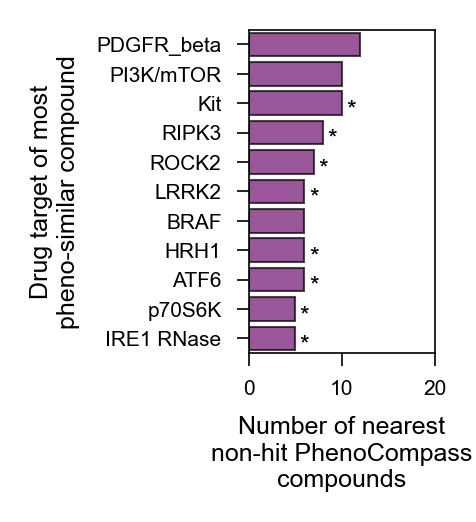

Figure data already exists


In [29]:
# --- Barplot: enrichment of nearest-neighbor drug targets (all non-hit PhenoCompass) ---
fig_path = os.path.join(FIGURE_DIR, "FigS11_cell_painting.non_pi3k_hit_effects.all.pdf")

plot_data = enrichment_df_all[enrichment_df_all["x"] >= 5].sort_values("x", ascending=False)
pval_lookup = dict(zip(enrichment_df_all["moa"], enrichment_df_all["p_value"]))

plt.figure(figsize=(0.8, 1.4))
ax = sns.barplot(x="x", y="moa", data=plot_data,
                 edgecolor="black", linewidth=0.5, color="purple", alpha=0.7)
plt.xlabel("Number of nearest\nnon-hit PhenoCompass\ncompounds")
plt.ylabel("Drug target of most\npheno-similar compound")
plt.xlim([0, 20])

for i, p in enumerate(ax.patches):
    p_value = pval_lookup[plot_data["moa"].values[i]]
    plt.text(1 + p.get_width(), p.get_y() + 0.82 * p.get_height(),
             "*" if p_value < 0.05 else "",
             ha="center", va="center",
             fontsize=6)

save_figure(fig_path, FORCE_RECOMPUTE)

# Save figure source data
fig_data_path = os.path.join(FIGURE_DIR, "FigS11_cell_painting.non_pi3k_hit_effects.tsv")
save_figure_data(enrichment_df_all, fig_data_path, FORCE_RECOMPUTE)

## 11. FOXO3A Nuclear Enrichment

Figure already exists


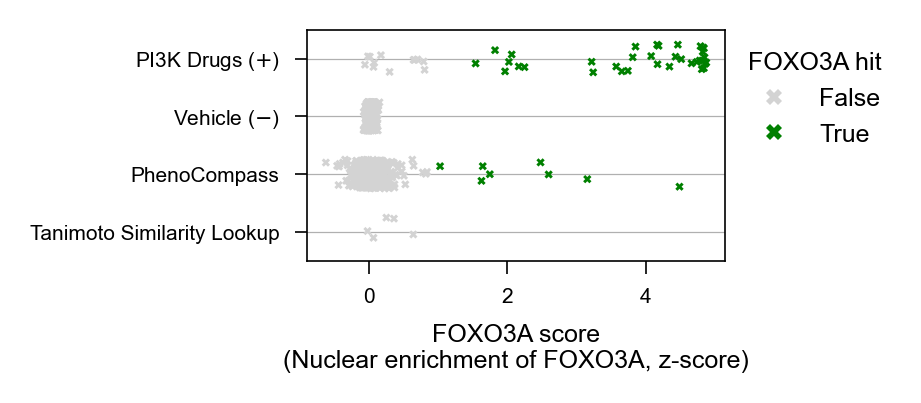

In [30]:
np.random.seed(0)

metric = "mean_clip_5"

foxo3a_category_name_dict = {
    "gProbe_Control": "PI3K Drugs" r" ($+$)",
    "JUMP_Control": "PI3K Drugs" r" ($+$)",
    "jump_anchor": "PhenoCompass",
    "pi3k_drug_anchor": "PhenoCompass\n(PI3K Drug Anchors)",
    "pi3k_high_ts": "Tanimoto Similarity Lookup",
    "Vehicle": "Vehicle" r" ($-$)",
    "None": "None",
}

rank_dict = {
    "PI3K Drugs" r" ($+$)": 0,
    "Vehicle" r" ($-$)": 1,
    "PhenoCompass": 2,
    "PhenoCompass\n(PI3K Drug Anchors)": 3,
    "Tanimoto Similarity Lookup": 4,
}

foxo3a_plot_df = foxo3a_z_df.copy()
foxo3a_plot_df["significant"] = foxo3a_plot_df[metric] > 1
foxo3a_plot_df["category_name"] = foxo3a_plot_df["prediction_category"].map(foxo3a_category_name_dict)
foxo3a_plot_df = foxo3a_plot_df[foxo3a_plot_df["category_name"] != "PhenoCompass\n(PI3K Drug Anchors)"]
foxo3a_plot_df["rank"] = [rank_dict[cat] for cat in foxo3a_plot_df["category_name"]]
foxo3a_plot_df.sort_values(["rank", "significant"], inplace=True)

fig_path = os.path.join(FIGURE_DIR, "Fig5_foxo3a_screen.nuclear_enrichment.pdf")

# --- Updated formatting to match previous anchor strip plot proportion/styling ---
plt.figure(figsize=(1.8, foxo3a_plot_df["category_name"].nunique() * 0.25))
sns.stripplot(
    x=metric,
    y="category_name",
    hue="significant",
    data=foxo3a_plot_df,
    s=2,
    jitter=0.25,
    palette=["lightgrey", "green"],
    marker="X"
)
plt.xlabel("FOXO3A score\n(Nuclear enrichment of FOXO3A, z-score)")
plt.ylabel("")
plt.grid(axis="y", linewidth=0.3)
plt.legend(
    bbox_to_anchor=(1, 1),
    title="FOXO3A hit",
    title_fontsize=6,
    markerscale=2
)

save_figure(fig_path, FORCE_RECOMPUTE)

## 13. mTOR/PI3K Anchor Cosine Similarity Heatmaps

Cosine similarity and cosine similarity quantile heatmaps for the 4 mTOR/PI3K
anchor compounds (Pemirolast, Paxalisib, CH-5132799, Torkinib) in both the
Cell Painting validation embeddings and the JUMP DINO-TVN embeddings.

In [31]:
smiles_name_map = {
    "CS(=O)(=O)N1CCc2c(-c3cnc(=N)[nH]c3)nc(N3CCOCC3)nc21": "CH-5132799",
    "CC1(C)OCCn2c1nc1c(N3CCOCC3)nc(-c3cnc(=N)[nH]c3)nc12": "Paxalisib",
    "Cc1cccn2c(=O)c(-c3nn[nH]n3)cnc12": "Pemirolast",
    "CC(C)n1nc(-c2cc3cc(O)ccc3[nH]2)c2c(N)ncnc21": "Torkinib",
}

compound_to_smiles = dict(zip(
    mtor_pi3k_anchors_df["COMPOUND_ID"],
    mtor_pi3k_anchors_df["canonical_SMILES"]
))

sorted_anchor_names = ["Pemirolast", "Paxalisib", "CH-5132799", "Torkinib"]


def plot_quantile_heatmap(quantile_df, fig_path):
    """Plot a cosine-similarity quantile heatmap with a horizontal colorbar on top."""
    cg = sns.clustermap(
        quantile_df,
        row_cluster=False, col_cluster=False,
        vmin=0, vmax=1, cmap="Reds",
        figsize=(1.7, 1.7), annot=True, annot_kws={"size": 5}, fmt=".2f",
        cbar_pos=(0.19, 0.9, 0.45, 0.03),
        cbar_kws={"orientation": "horizontal"},
    )
    cg.ax_row_dendrogram.set_visible(False)
    cg.ax_col_dendrogram.set_visible(False)
    cg.cax.set_title("Quantile", fontsize=5, pad=4)
    cg.cax.tick_params(labelsize=4)
    save_figure(fig_path, FORCE_RECOMPUTE)
    return cg


In [32]:
mtor_pi3k_jump_anchors = cp_features_df[cp_features_df["Metadata_Category"].isin(["PI3K/mTOR Anchors", "PI3K/mTOR Anchors (ignore)"])]["Metadata_COMPOUND_ID"].unique().tolist()

Figure already exists


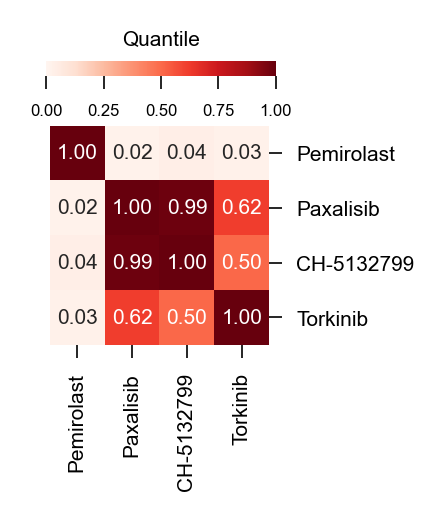

In [33]:
# --- Cell Painting: anchor cosine similarity heatmaps ---

cp_adata = filtered_adata.copy()

cp_all_cossim = cosine_similarity(cp_adata[~cp_adata.obs["Metadata_COMPOUND_ID"].isin(mtor_pi3k_jump_anchors)].X).flatten()

cp_anchors_adata = cp_adata[cp_adata.obs["Metadata_COMPOUND_ID"].isin(mtor_pi3k_jump_anchors)]
cp_anchors_adata.obs.index = cp_anchors_adata.obs["Metadata_COMPOUND_ID"]
cp_anchors_adata.obs["name"] = cp_anchors_adata.obs["Metadata_COMPOUND_ID"].map(compound_to_smiles).map(smiles_name_map)

cp_cossim = cosine_similarity(cp_anchors_adata.X)
cp_cossim_quantile = (np.expand_dims(cp_cossim, 2) >= cp_all_cossim).mean(2)

anchor_name_map = dict(zip(sorted_anchor_names, sorted(mtor_pi3k_jump_anchors)))

cp_quantile_df = pd.DataFrame(
    cp_cossim_quantile,
    index=cp_anchors_adata.obs["name"].values,
    columns=cp_anchors_adata.obs["name"].values,
)

fig_path = os.path.join(FIGURE_DIR, "FigS11_mtor_pi3k_anchors.cossim.validation_cp.quantile.heatmap.pdf")
plot_quantile_heatmap(cp_quantile_df, fig_path)

Figure already exists


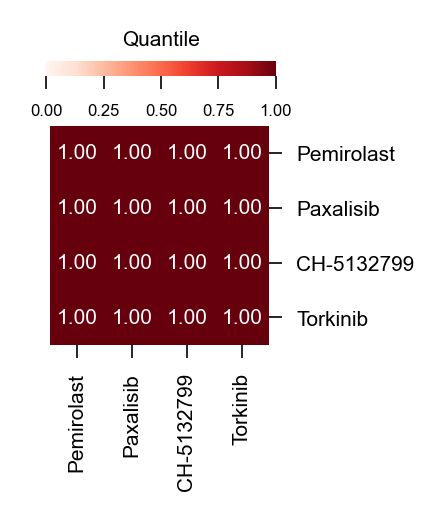

Figure data already exists


In [34]:
# --- DINO-TVN: anchor cosine similarity heatmaps ---

np.random.seed(0)
jump_img_representations_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "embeddings/image/dino_image_embeddings.parquet"))
mtor_pi3k_anchors_with_ids_df = mtor_pi3k_anchors_df[~mtor_pi3k_anchors_df["COMPOUND_ID"].isna()]

dino_subset_df = jump_img_representations_df.loc[mtor_pi3k_anchors_with_ids_df["canonical_SMILES"].values]
dino_subset_df.index = dino_subset_df.index.map(smiles_name_map)

dino_anchor_rows = dino_subset_df.loc[sorted_anchor_names]
non_mtor_pi3k_anchors_smiles = list(set(jump_img_representations_df.index.values) - set(mtor_pi3k_anchors_df["canonical_SMILES"].values))
dino_background_smiles = np.random.choice(non_mtor_pi3k_anchors_smiles, size=10000, replace=False)
dino_background_rows = jump_img_representations_df.loc[dino_background_smiles]

dino_all_cossim = cosine_similarity(dino_background_rows.values)
dino_all_cossim = dino_all_cossim[np.triu_indices(len(dino_all_cossim), 1)]

dino_cossim = cosine_similarity(dino_anchor_rows.values)
dino_cossim_quantile = (np.expand_dims(dino_cossim, 2) >= dino_all_cossim).mean(2)

dino_quantile_df = pd.DataFrame(
    dino_cossim_quantile,
    index=sorted_anchor_names,
    columns=sorted_anchor_names,
)

fig_path = os.path.join(FIGURE_DIR, "FigS11_mtor_pi3k_anchors.cossim.jump_dino.quantile.heatmap.pdf")
plot_quantile_heatmap(dino_quantile_df, fig_path)

# Save heatmap data for both CP and DINO quantile matrices
heatmap_records = []
for source, qdf in [("validation_cp", cp_quantile_df), ("jump_dino", dino_quantile_df)]:
    for row_name in qdf.index:
        for col_name in qdf.columns:
            heatmap_records.append({
                "source": source,
                "row_anchor": row_name,
                "col_anchor": col_name,
                "quantile": qdf.loc[row_name, col_name],
            })
heatmap_data_df = pd.DataFrame(heatmap_records)
fig_data_path = os.path.join(FIGURE_DIR, "FigS11_mtor_pi3k_anchors_cossim_data.tsv")
save_figure_data(heatmap_data_df, fig_data_path, FORCE_RECOMPUTE)